# Recommendation System Offline Evaluation

This notebook evaluates the personalised learning-resource recommendation component using a separately constructed labelled sample of student profiles and student-resource relevance pairs.

Recommendation quality is measured using Precision@5 and Mean Reciprocal Rank (MRR). Additional experiments examine the contribution of the ranking components through ablation testing and compare the personalised method with a non-personalised baseline.

In [6]:
import pandas as pd
import numpy as np
import json
import sys
from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
current_path = Path.cwd()

if (current_path / "data").exists():
    PROJECT_ROOT = current_path

elif (current_path.parent / "data").exists():
    PROJECT_ROOT = current_path.parent

else:
    raise FileNotFoundError(
        "Could not locate the project root."
    )

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\abdoo_\OneDrive\Documenten\Personalized_Learning_System


In [8]:
resources_path = (
    PROJECT_ROOT
    / "data"
    / "recommendation"
    / "learning_resources.csv"
)

profiles_path = (
    PROJECT_ROOT
    / "data"
    / "evaluation"
    / "recommendation_evaluation_profiles.csv"
)

labels_path = (
    PROJECT_ROOT
    / "data"
    / "evaluation"
    / "recommendation_relevance_labels.csv"
)

In [9]:
recommender_path = (
    PROJECT_ROOT
    / "recommendation"
    / "recommender.py"
)

print("Resources found:", resources_path.exists())
print("Profiles found:", profiles_path.exists())
print("Labels found:", labels_path.exists())
print("Recommender found:", recommender_path.exists())

Resources found: True
Profiles found: True
Labels found: True
Recommender found: True


In [10]:
resources_df = pd.read_csv(resources_path)
profiles_df = pd.read_csv(profiles_path)
labels_df = pd.read_csv(labels_path)

print("Learning resources:", resources_df.shape)
print("Evaluation profiles:", profiles_df.shape)
print("Relevance labels:", labels_df.shape)

Learning resources: (70, 11)
Evaluation profiles: (20, 6)
Relevance labels: (140, 3)


In [11]:
display(resources_df.head())
display(profiles_df.head())
display(labels_df.head())

,Resource_ID,Resource_Name,Provider,Academic_Area,Primary_Topic,Related_Topics,Supports_Skill,Difficulty_Level,Resource_Type,Description,URL
0,R001,Introduction to Marketing,University of Pennsylvania / Coursera,Business & Management,Marketing,Branding; Customer Analysis; Marketing Strategy,Business Analysis,Beginner,Course,Introduces core marketing concepts including b...,https://www.coursera.org/learn/wharton-marketing
1,R002,Introduction to Financial Accounting,University of Pennsylvania / Coursera,Business & Management,Accounting,Financial Statements; Financial Analysis; Book...,Quantitative Skills,Beginner,Course,Builds foundational skills for reading and int...,https://www.coursera.org/learn/wharton-accounting
2,R003,Introduction to Operations Management,University of Pennsylvania / Coursera,Business & Management,Operations Management,Process Analysis; Flow; Variability; Operation...,Strategic Thinking,Beginner,Course,"Introduces process analysis, operational flow,...",https://www.coursera.org/learn/wharton-operations
3,R004,Understand Human Resource Management Fundamentals,Coursera,Business & Management,Human Resource Management,Talent Management; Recruitment; Performance Ma...,Business Analysis,Beginner,Course,"Covers core HR functions, talent acquisition, ...",https://www.coursera.org/learn/understand-huma...
4,R005,Business Strategy,University of Illinois Urbana-Champaign / Cour...,Business & Management,Business Strategy,Competitive Advantage; SWOT; Business Models,Strategic Thinking,Intermediate,Course,Develops strategic analysis skills for underst...,https://www.coursera.org/learn/strategy-business


,Profile_ID,Academic_Area,Confidence_Scores,Interests,Academic_Goal,Pass_Probability
0,E01,Business & Management,"{""Business Analysis"": 2, ""Quantitative Skills""...",Marketing; Customer Analysis,Strengthen core academic skills,42
1,E02,Business & Management,"{""Business Analysis"": 4, ""Quantitative Skills""...",Business Analytics; Decision Making,Develop advanced subject knowledge,68
2,E03,Computing & IT,"{""Computer Systems"": 2, ""Programming"": 4, ""Dat...",Networking; Cybersecurity,Strengthen core academic skills,44
3,E04,Computing & IT,"{""Computer Systems"": 4, ""Programming"": 3, ""Dat...",Programming; Software Development,Develop advanced subject knowledge,72
4,E05,Data Science & AI,"{""Programming"": 2, ""Mathematics & Statistics"":...",Python; Programming Fundamentals,Strengthen core academic skills,45


,Profile_ID,Resource_ID,Relevant
0,E01,R001,1
1,E01,R002,0
2,E01,R003,0
3,E01,R004,1
4,E01,R005,0


In [12]:
print("Missing values in resources:")
print(resources_df.isnull().sum())

print("\nMissing values in profiles:")
print(profiles_df.isnull().sum())

print("\nMissing values in labels:")
print(labels_df.isnull().sum())

Missing values in resources:
Resource_ID         0
Resource_Name       0
Provider            0
Academic_Area       0
Primary_Topic       0
Related_Topics      0
Supports_Skill      0
Difficulty_Level    0
Resource_Type       0
Description         0
URL                 0
dtype: int64

Missing values in profiles:
Profile_ID           0
Academic_Area        0
Confidence_Scores    0
Interests            0
Academic_Goal        0
Pass_Probability     0
dtype: int64

Missing values in labels:
Profile_ID     0
Resource_ID    0
Relevant       0
dtype: int64


In [13]:
profiles_df["Confidence_Scores"] = (
    profiles_df["Confidence_Scores"]
    .apply(json.loads)
)

profiles_df["Interests"] = (
    profiles_df["Interests"]
    .apply(
        lambda x: [
            item.strip()
            for item in str(x).split(";")
            if item.strip()
        ]
    )
)

display(profiles_df.head())

,Profile_ID,Academic_Area,Confidence_Scores,Interests,Academic_Goal,Pass_Probability
0,E01,Business & Management,"{'Business Analysis': 2, 'Quantitative Skills'...","[Marketing, Customer Analysis]",Strengthen core academic skills,42
1,E02,Business & Management,"{'Business Analysis': 4, 'Quantitative Skills'...","[Business Analytics, Decision Making]",Develop advanced subject knowledge,68
2,E03,Computing & IT,"{'Computer Systems': 2, 'Programming': 4, 'Dat...","[Networking, Cybersecurity]",Strengthen core academic skills,44
3,E04,Computing & IT,"{'Computer Systems': 4, 'Programming': 3, 'Dat...","[Programming, Software Development]",Develop advanced subject knowledge,72
4,E05,Data Science & AI,"{'Programming': 2, 'Mathematics & Statistics':...","[Python, Programming Fundamentals]",Strengthen core academic skills,45


In [14]:
recommendation_folder = (
    PROJECT_ROOT
    / "recommendation"
)

if str(recommendation_folder) not in sys.path:
    sys.path.append(
        str(recommendation_folder)
    )

from recommender import recommend_resources

print("Recommender imported successfully.")

Recommender imported successfully.


In [15]:
student = profiles_df.iloc[0]

print("Profile:", student["Profile_ID"])
print("Academic Area:", student["Academic_Area"])
print("Confidence:", student["Confidence_Scores"])
print("Interests:", student["Interests"])
print("Pass Probability:", student["Pass_Probability"])

Profile: E01
Academic Area: Business & Management
Confidence: {'Business Analysis': 2, 'Quantitative Skills': 4, 'Strategic Thinking': 4}
Interests: ['Marketing', 'Customer Analysis']
Pass Probability: 42


In [16]:
result = recommend_resources(
    resources_df=resources_df,
    academic_area=student["Academic_Area"],
    confidence_scores=student["Confidence_Scores"],
    interests=student["Interests"],
    academic_goal=student["Academic_Goal"],
    pass_probability=student["Pass_Probability"],
    top_n=5
)

top_recommendations = result[
    "top_recommendations"
]

In [17]:
display(
    top_recommendations[
        [
            "Resource_ID",
            "Resource_Name",
            "Supports_Skill",
            "Difficulty_Level",
            "Recommendation_Score"
        ]
    ]
)

,Resource_ID,Resource_Name,Supports_Skill,Difficulty_Level,Recommendation_Score
0,R001,Introduction to Marketing,Business Analysis,Beginner,0.787718
3,R004,Understand Human Resource Management Fundamentals,Business Analysis,Beginner,0.463024
1,R002,Introduction to Financial Accounting,Quantitative Skills,Beginner,0.281469
5,R006,Introduction to Business Analytics,Quantitative Skills,Beginner,0.275070
2,R003,Introduction to Operations Management,Strategic Thinking,Beginner,0.272152


## Offline Recommendation Evaluation

The final personalised recommender is evaluated across all labelled student profiles using Precision@5 and Mean Reciprocal Rank (MRR). Precision@5 measures the proportion of the top five recommended resources that are labelled as relevant, while MRR measures how highly the first relevant resource appears in the ranked results.

In [18]:
def precision_at_k(
    recommended_ids,
    relevant_ids,
    k=5
):
    top_k = recommended_ids[:k]

    relevant_count = sum(
        resource_id in relevant_ids
        for resource_id in top_k
    )

    return relevant_count / k


def reciprocal_rank(
    recommended_ids,
    relevant_ids
):
    for rank, resource_id in enumerate(
        recommended_ids,
        start=1
    ):
        if resource_id in relevant_ids:
            return 1 / rank

    return 0.0

In [19]:
evaluation_results = []

for _, student in profiles_df.iterrows():

    profile_id = student["Profile_ID"]

    relevant_ids = set(
        labels_df[
            (labels_df["Profile_ID"] == profile_id)
            & (labels_df["Relevant"] == 1)
        ]["Resource_ID"]
    )

    result = recommend_resources(
        resources_df=resources_df,
        academic_area=student["Academic_Area"],
        confidence_scores=student["Confidence_Scores"],
        interests=student["Interests"],
        academic_goal=student["Academic_Goal"],
        pass_probability=student["Pass_Probability"],
        top_n=5
    )

    recommendations = result[
        "top_recommendations"
    ]

    recommended_ids = (
        recommendations["Resource_ID"]
        .tolist()
    )

    p_at_5 = precision_at_k(
        recommended_ids,
        relevant_ids,
        k=5
    )

    rr = reciprocal_rank(
        recommended_ids,
        relevant_ids
    )

    evaluation_results.append({
        "Profile_ID": profile_id,
        "Academic_Area": student["Academic_Area"],
        "Relevant_Resources": ", ".join(
            sorted(relevant_ids)
        ),
        "Top_5_Recommendations": ", ".join(
            recommended_ids
        ),
        "Precision@5": p_at_5,
        "Reciprocal_Rank": rr
    })


evaluation_df = pd.DataFrame(
    evaluation_results
)

display(evaluation_df)

,Profile_ID,Academic_Area,Relevant_Resources,Top_5_Recommendations,Precision@5,Reciprocal_Rank
0,E01,Business & Management,"R001, R004","R001, R004, R002, R006, R003",0.4,1.0
1,E02,Business & Management,"R006, R007","R007, R006, R002, R005, R004",0.4,1.0
2,E03,Computing & IT,"R008, R011","R008, R011, R012, R013, R009",0.4,1.0
3,E04,Computing & IT,"R009, R014","R014, R009, R008, R012, R013",0.4,1.0
4,E05,Data Science & AI,R016,"R016, R019, R020, R015, R017",0.2,1.0
5,E06,Data Science & AI,"R019, R020, R021","R019, R021, R020, R017, R018",0.6,1.0
6,E07,Engineering & Technology,R022,"R022, R023, R025, R024, R027",0.2,1.0
7,E08,Engineering & Technology,"R024, R025","R024, R025, R026, R023, R022",0.4,1.0
8,E09,Psychology & Health Sciences,"R029, R030","R029, R030, R031, R033, R035",0.4,1.0
9,E10,Psychology & Health Sciences,R032,"R032, R029, R031, R035, R033",0.2,1.0


In [20]:
mean_precision_at_5 = (
    evaluation_df["Precision@5"].mean()
)

mrr = (
    evaluation_df["Reciprocal_Rank"].mean()
)

print(
    "Mean Precision@5:",
    round(mean_precision_at_5, 4)
)

print(
    "Mean Reciprocal Rank (MRR):",
    round(mrr, 4)
)

Mean Precision@5: 0.37
Mean Reciprocal Rank (MRR): 1.0


In [21]:
evaluation_output_path = (
    PROJECT_ROOT
    / "data"
    / "evaluation"
    / "personalised_recommender_results.csv"
)

evaluation_df.to_csv(
    evaluation_output_path,
    index=False
)

print(
    "Results saved to:",
    evaluation_output_path
)

Results saved to: c:\Users\abdoo_\OneDrive\Documenten\Personalized_Learning_System\data\evaluation\personalised_recommender_results.csv


## Ablation Study

An ablation study is used to examine the contribution of the individual components in the recommendation ranking. The full weighting configuration is compared with alternative configurations where one component is removed at a time. The remaining weights are normalised so that their relative contribution continues to sum to 1.

In [22]:
def rank_with_weights(
    student,
    skill_weight=0.35,
    interest_weight=0.25,
    similarity_weight=0.25,
    difficulty_weight=0.15,
    top_n=5
):

    # Generate the component scores using
    # the existing recommendation logic
    result = recommend_resources(
        resources_df=resources_df,
        academic_area=student["Academic_Area"],
        confidence_scores=student["Confidence_Scores"],
        interests=student["Interests"],
        academic_goal=student["Academic_Goal"],
        pass_probability=student["Pass_Probability"],
        top_n=len(resources_df)
    )

    candidates = result[
        "top_recommendations"
    ].copy()

    # Normalise the selected weights
    total_weight = (
        skill_weight
        + interest_weight
        + similarity_weight
        + difficulty_weight
    )

    if total_weight == 0:
        raise ValueError(
            "At least one weight must be greater than zero."
        )

    skill_weight = (
        skill_weight / total_weight
    )

    interest_weight = (
        interest_weight / total_weight
    )

    similarity_weight = (
        similarity_weight / total_weight
    )

    difficulty_weight = (
        difficulty_weight / total_weight
    )

    # Recalculate the recommendation score
    candidates["Ablation_Score"] = (
        candidates["Skill_Need_Score"]
        * skill_weight

        + candidates["Interest_Score"]
        * interest_weight

        + candidates["Similarity_Score"]
        * similarity_weight

        + candidates["Difficulty_Score"]
        * difficulty_weight
    )

    # Rank again using the new weights
    candidates = candidates.sort_values(
        by="Ablation_Score",
        ascending=False
    )

    return candidates.head(top_n)

In [23]:
ablation_configs = {
    "Full Recommender": {
        "skill_weight": 0.35,
        "interest_weight": 0.25,
        "similarity_weight": 0.25,
        "difficulty_weight": 0.15
    },

    "No Skill Need": {
        "skill_weight": 0.00,
        "interest_weight": 0.25,
        "similarity_weight": 0.25,
        "difficulty_weight": 0.15
    },

    "No Interest": {
        "skill_weight": 0.35,
        "interest_weight": 0.00,
        "similarity_weight": 0.25,
        "difficulty_weight": 0.15
    },

    "No Similarity": {
        "skill_weight": 0.35,
        "interest_weight": 0.25,
        "similarity_weight": 0.00,
        "difficulty_weight": 0.15
    },

    "No Difficulty": {
        "skill_weight": 0.35,
        "interest_weight": 0.25,
        "similarity_weight": 0.25,
        "difficulty_weight": 0.00
    }
}

In [25]:
ablation_results = []

for config_name, weights in ablation_configs.items():

    precision_3_scores = []
    precision_5_scores = []
    reciprocal_ranks = []

    for _, student in profiles_df.iterrows():

        profile_id = student["Profile_ID"]

        relevant_ids = set(
            labels_df[
                (labels_df["Profile_ID"] == profile_id)
                & (labels_df["Relevant"] == 1)
            ]["Resource_ID"]
        )

        ranked_resources = rank_with_weights(
            student=student,
            **weights,
            top_n=5
        )

        recommended_ids = (
            ranked_resources["Resource_ID"]
            .tolist()
        )

        precision_3_scores.append(
            precision_at_k(
                recommended_ids,
                relevant_ids,
                k=3
            )
        )

        precision_5_scores.append(
            precision_at_k(
                recommended_ids,
                relevant_ids,
                k=5
            )
        )

        reciprocal_ranks.append(
            reciprocal_rank(
                recommended_ids,
                relevant_ids
            )
        )

    ablation_results.append({
        "Configuration": config_name,
        "Precision@3": np.mean(
            precision_3_scores
        ),
        "Precision@5": np.mean(
            precision_5_scores
        ),
        "MRR": np.mean(
            reciprocal_ranks
        )
    })


ablation_df = pd.DataFrame(
    ablation_results
)

display(
    ablation_df.round(4)
)

,Configuration,Precision@3,Precision@5,MRR
0,Full Recommender,0.6167,0.37,1.0
1,No Skill Need,0.6167,0.37,1.0
2,No Interest,0.5833,0.37,1.0
3,No Similarity,0.6167,0.37,1.0
4,No Difficulty,0.6167,0.37,1.0


### Ranking Change Analysis

Since some ablation configurations produced the same Precision@3, Precision@5 and MRR values as the full recommender, an additional comparison was carried out to examine whether removing individual ranking components changed the ordering of the recommended resources.

In [31]:
def get_ranked_ids(
    student,
    weights,
    top_n=5
):
    ranked = rank_with_weights(
        student=student,
        **weights,
        top_n=top_n
    )

    return ranked["Resource_ID"].tolist()

In [32]:
full_weights = ablation_configs[
    "Full Recommender"
]

ranking_change_results = []

for config_name, weights in ablation_configs.items():

    if config_name == "Full Recommender":
        continue

    changed_profiles = 0
    total_position_changes = 0

    for _, student in profiles_df.iterrows():

        full_ranking = get_ranked_ids(
            student,
            full_weights,
            top_n=5
        )

        ablated_ranking = get_ranked_ids(
            student,
            weights,
            top_n=5
        )

        if full_ranking != ablated_ranking:
            changed_profiles += 1

        position_changes = sum(
            full_resource != ablated_resource
            for full_resource, ablated_resource
            in zip(
                full_ranking,
                ablated_ranking
            )
        )

        total_position_changes += (
            position_changes
        )

    ranking_change_results.append({
        "Configuration": config_name,
        "Profiles_With_Ranking_Change":
            changed_profiles,
        "Percentage_Changed":
            changed_profiles
            / len(profiles_df)
            * 100,
        "Total_Position_Changes":
            total_position_changes
    })


ranking_change_df = pd.DataFrame(
    ranking_change_results
)

display(
    ranking_change_df.round(2)
)

,Configuration,Profiles_With_Ranking_Change,Percentage_Changed,Total_Position_Changes
0,No Skill Need,13,65.0,37
1,No Interest,7,35.0,20
2,No Similarity,2,10.0,4
3,No Difficulty,7,35.0,12


## Non-Personalised Baseline Comparison

A simple non-personalised baseline is used to provide a reference point for evaluating the personalised recommendation approach. The baseline selects resources from the student's chosen academic area but does not consider confidence ratings, interests, academic goal, predicted performance or similarity-based matching. Resources are returned according to their existing catalogue order.

The baseline and personalised recommender are evaluated using the same student profiles and relevance labels to allow a consistent comparison.

In [26]:
def baseline_recommend_resources(
    resources_df,
    academic_area,
    top_n=5
):
    candidates = resources_df[
        resources_df["Academic_Area"]
        == academic_area
    ].copy()

    return candidates.head(top_n)

In [27]:
student = profiles_df.iloc[0]

baseline_test = baseline_recommend_resources(
    resources_df=resources_df,
    academic_area=student["Academic_Area"],
    top_n=5
)

display(
    baseline_test[
        [
            "Resource_ID",
            "Resource_Name",
            "Supports_Skill",
            "Difficulty_Level"
        ]
    ]
)

,Resource_ID,Resource_Name,Supports_Skill,Difficulty_Level
0,R001,Introduction to Marketing,Business Analysis,Beginner
1,R002,Introduction to Financial Accounting,Quantitative Skills,Beginner
2,R003,Introduction to Operations Management,Strategic Thinking,Beginner
3,R004,Understand Human Resource Management Fundamentals,Business Analysis,Beginner
4,R005,Business Strategy,Strategic Thinking,Intermediate


In [28]:
baseline_results = []

for _, student in profiles_df.iterrows():

    profile_id = student["Profile_ID"]

    relevant_ids = set(
        labels_df[
            (labels_df["Profile_ID"] == profile_id)
            & (labels_df["Relevant"] == 1)
        ]["Resource_ID"]
    )

    recommendations = (
        baseline_recommend_resources(
            resources_df=resources_df,
            academic_area=student["Academic_Area"],
            top_n=5
        )
    )

    recommended_ids = (
        recommendations["Resource_ID"]
        .tolist()
    )

    p_at_3 = precision_at_k(
        recommended_ids,
        relevant_ids,
        k=3
    )

    p_at_5 = precision_at_k(
        recommended_ids,
        relevant_ids,
        k=5
    )

    rr = reciprocal_rank(
        recommended_ids,
        relevant_ids
    )

    baseline_results.append({
        "Profile_ID": profile_id,
        "Academic_Area": student["Academic_Area"],
        "Top_5_Recommendations": ", ".join(
            recommended_ids
        ),
        "Precision@3": p_at_3,
        "Precision@5": p_at_5,
        "Reciprocal_Rank": rr
    })


baseline_df = pd.DataFrame(
    baseline_results
)

display(
    baseline_df.round(4)
)

,Profile_ID,Academic_Area,Top_5_Recommendations,Precision@3,Precision@5,Reciprocal_Rank
0,E01,Business & Management,"R001, R002, R003, R004, R005",0.3333,0.4,1.0000
1,E02,Business & Management,"R001, R002, R003, R004, R005",0.0000,0.0,0.0000
2,E03,Computing & IT,"R008, R009, R010, R011, R012",0.3333,0.4,1.0000
3,E04,Computing & IT,"R008, R009, R010, R011, R012",0.3333,0.2,0.5000
4,E05,Data Science & AI,"R015, R016, R017, R018, R019",0.3333,0.2,0.5000
5,E06,Data Science & AI,"R015, R016, R017, R018, R019",0.0000,0.2,0.2000
6,E07,Engineering & Technology,"R022, R023, R024, R025, R026",0.3333,0.2,1.0000
7,E08,Engineering & Technology,"R022, R023, R024, R025, R026",0.3333,0.4,0.3333
8,E09,Psychology & Health Sciences,"R029, R030, R031, R032, R033",0.6667,0.4,1.0000
9,E10,Psychology & Health Sciences,"R029, R030, R031, R032, R033",0.0000,0.2,0.2500


In [29]:
baseline_precision_3 = (
    baseline_df["Precision@3"].mean()
)

baseline_precision_5 = (
    baseline_df["Precision@5"].mean()
)

baseline_mrr = (
    baseline_df[
        "Reciprocal_Rank"
    ].mean()
)

print(
    "Baseline Precision@3:",
    round(baseline_precision_3, 4)
)

print(
    "Baseline Precision@5:",
    round(baseline_precision_5, 4)
)

print(
    "Baseline MRR:",
    round(baseline_mrr, 4)
)

Baseline Precision@3: 0.3
Baseline Precision@5: 0.27
Baseline MRR: 0.585


In [30]:
personalised_precision_3 = (
    ablation_df.loc[
        ablation_df["Configuration"]
        == "Full Recommender",
        "Precision@3"
    ].iloc[0]
)

personalised_precision_5 = (
    ablation_df.loc[
        ablation_df["Configuration"]
        == "Full Recommender",
        "Precision@5"
    ].iloc[0]
)

personalised_mrr = (
    ablation_df.loc[
        ablation_df["Configuration"]
        == "Full Recommender",
        "MRR"
    ].iloc[0]
)


comparison_df = pd.DataFrame({
    "Method": [
        "Non-Personalised Baseline",
        "Personalised Recommender"
    ],

    "Precision@3": [
        baseline_precision_3,
        personalised_precision_3
    ],

    "Precision@5": [
        baseline_precision_5,
        personalised_precision_5
    ],

    "MRR": [
        baseline_mrr,
        personalised_mrr
    ]
})


display(
    comparison_df.round(4)
)

,Method,Precision@3,Precision@5,MRR
0,Non-Personalised Baseline,0.3000,0.27,0.585
1,Personalised Recommender,0.6167,0.37,1.000


In [33]:
ablation_output_path = (
    PROJECT_ROOT
    / "data"
    / "evaluation"
    / "ablation_results.csv"
)

comparison_output_path = (
    PROJECT_ROOT
    / "data"
    / "evaluation"
    / "baseline_comparison.csv"
)

ranking_output_path = (
    PROJECT_ROOT
    / "data"
    / "evaluation"
    / "ablation_ranking_changes.csv"
)

ablation_df.to_csv(
    ablation_output_path,
    index=False
)

comparison_df.to_csv(
    comparison_output_path,
    index=False
)

ranking_change_df.to_csv(
    ranking_output_path,
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


## Evaluation Visualisations

The following figures summarise the main results of the offline recommendation evaluation.

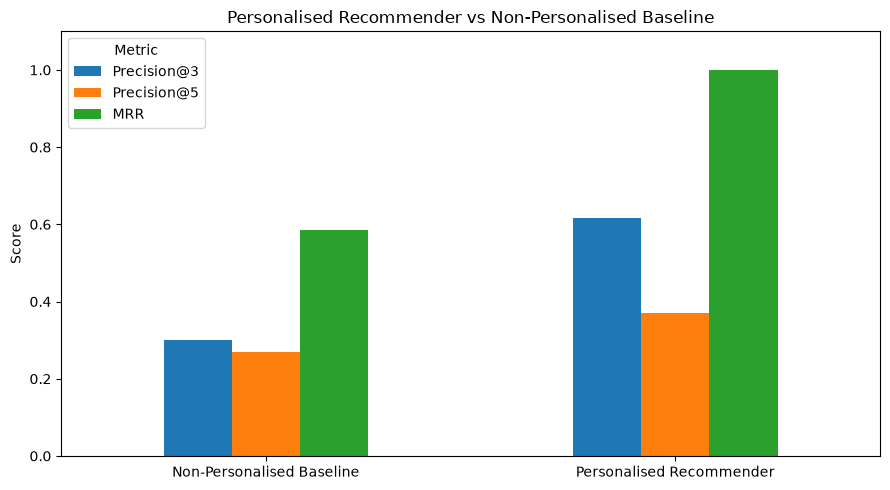

In [34]:
import matplotlib.pyplot as plt

figures_dir = (
    PROJECT_ROOT
    / "data"
    / "evaluation"
    / "figures"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

comparison_plot = (
    comparison_df
    .set_index("Method")[
        [
            "Precision@3",
            "Precision@5",
            "MRR"
        ]
    ]
)

ax = comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title(
    "Personalised Recommender vs Non-Personalised Baseline"
)

ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.1)

plt.xticks(rotation=0)

plt.legend(
    title="Metric"
)

plt.tight_layout()

plt.savefig(
    figures_dir / "baseline_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

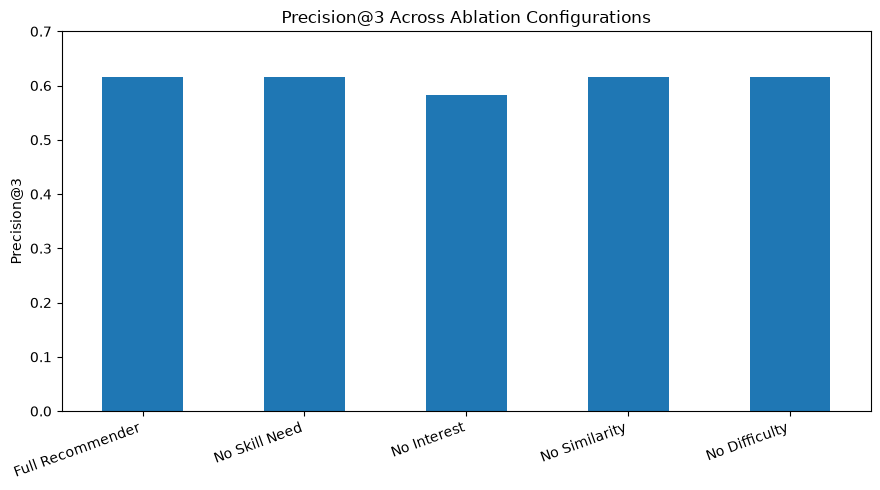

In [35]:
ablation_plot = (
    ablation_df[
        [
            "Configuration",
            "Precision@3"
        ]
    ]
    .set_index("Configuration")
)

ax = ablation_plot.plot(
    kind="bar",
    figsize=(9, 5),
    legend=False
)

ax.set_title(
    "Precision@3 Across Ablation Configurations"
)

ax.set_ylabel("Precision@3")
ax.set_xlabel("")
ax.set_ylim(0, 0.7)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    figures_dir / "ablation_precision_at_3.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()